In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sps
np.random.seed(0)
DATA_DIR = "data"

In [28]:
import importlib
import fingerprint as fp   # all the fingerprinting building blocks (see fingerprint.py)
importlib.reload(fp)

# Match the sample rate configured in fingerprint.py
SR = fp.SR          # 8000 Hz 
song_folder = os.path.join(DATA_DIR, "songs")
song_files = fp.list_songs(song_folder)

if song_files:
    print(f"Loaded {len(song_files)} songs from '{song_folder}'.")
    # Use fp.load_audio instead of fp.load_wav
    songs_audio = {name: fp.load_audio(path, target_sr=SR)[0] for name, path in song_files}
else:
    print("No real songs found")

for name, audio in songs_audio.items():
    print(f"  {name}: {len(audio)/SR:.1f} s")

Loaded 3 songs from 'data/songs'.
  song1: 217.2 s
  song2: 212.7 s
  song3: 183.6 s


## Why a single Fourier Transform is not enough:

A plain DFT of the *entire* song tells us **which** frequencies are present but says nothing about **when** they occurred. All timing information is collapsed away by the transform.

[ 1.8184744e-06 -8.6088394e-06 -3.0091212e-05 ...  4.8769050e-07
  9.0217617e-07  1.8148978e-07]
[-1.0910302e+02+0.0000000e+00j -2.1226699e+00+4.9115708e-01j
  3.3133025e+00-1.9311181e+00j ... -1.3693903e-05+6.2805884e-06j
 -2.0157471e-05+5.4617380e-05j -5.1317584e-05+0.0000000e+00j]
[0.00000000e+00 4.60330185e-03 9.20660370e-03 ... 1.10249908e+04
 1.10249954e+04 1.10250000e+04]


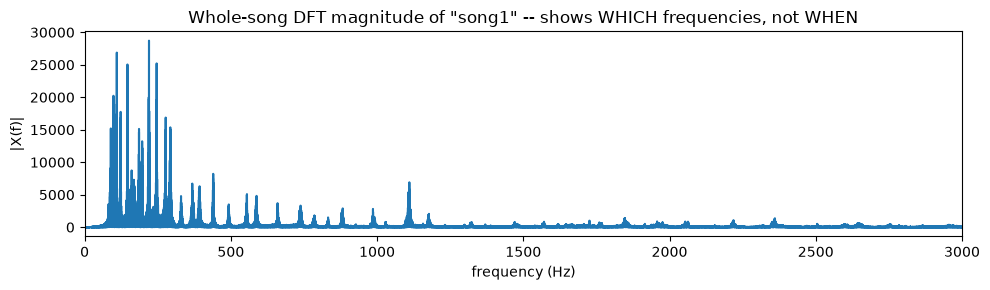

In [23]:
example_name = list(songs_audio.keys())[0]
example_audio = songs_audio[example_name]
print(example_audio)
X = np.fft.rfft(example_audio)
print(X)
freqs = np.fft.rfftfreq(len(example_audio), d=1/SR)
print(freqs)
plt.figure(figsize=(10,3))
plt.plot(freqs, np.abs(X))
plt.xlim(0, 3000)
plt.xlabel('frequency (Hz)'); plt.ylabel('|X(f)|')
plt.title(f'Whole-song DFT magnitude of "{example_name}" -- shows WHICH frequencies, not WHEN')
plt.tight_layout(); plt.show()

## Spectrogram: short window vs long window

Sliding a short window along the signal and taking its DFT at each position gives a
**spectrogram**, which is the frequency as a function of time. 

- **Short window:** good **time resolution** (we can tell exactly when a note starts/stops) but poor **frequency resolution** (narrow tones look blurred).
- **Long window:** good **frequency resolution** (narrow, precise frequency lines) but poor **time resolution** (note's on/off time is blurred).

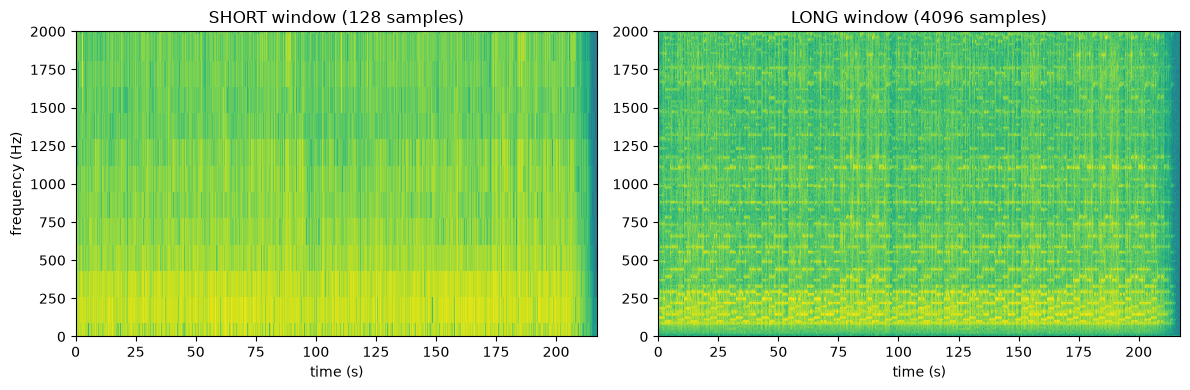

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, nperseg, label in zip(axes, [128, 4096], ["SHORT window (128 samples)", "LONG window (4096 samples)"]):
    f_spec, t_spec, Sxx = fp.spectrogram(example_audio, SR, nperseg=nperseg)
    ax.pcolormesh(t_spec, f_spec, 20*np.log10(Sxx+1e-9), shading='auto')
    ax.set_ylim(0, 2000)
    ax.set_title(label)
    ax.set_xlabel('time (s)')
axes[0].set_ylabel('frequency (Hz)')
plt.tight_layout(); plt.show()

## Building the fingerprint:

We keep only the **strongest local-maxima points** of the spectrogram (the "constellation"),
then pair nearby peaks into compact **hashes**: (f1, f2, delta t) two frequencies and the time gap between them, anchored at t1.

Found 2513 constellation peaks in 'song1'


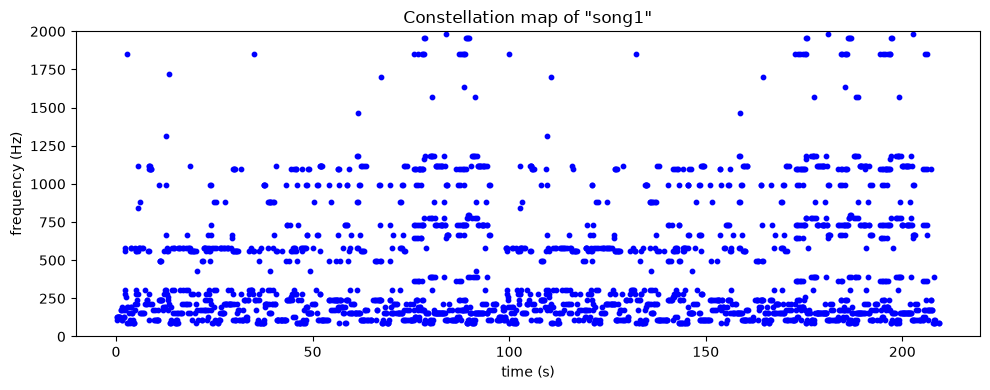

In [25]:
f_spec, t_spec, Sxx = fp.spectrogram(example_audio, SR, nperseg=1024)
peaks = fp.find_peaks_2d(Sxx)
print(f"Found {len(peaks)} constellation peaks in '{example_name}'")

plt.figure(figsize=(10,4))
#plt.pcolormesh(t_spec, f_spec, 20*np.log10(Sxx+1e-9), shading='auto', cmap='gray_r')
freq_idx = [p[0] for p in peaks]; time_idx = [p[1] for p in peaks]
plt.scatter(t_spec[time_idx], f_spec[freq_idx], c='blue', s=10)
plt.ylim(0, 2000)
plt.xlabel('time (s)'); plt.ylabel('frequency (Hz)')
plt.title(f'Constellation map of "{example_name}"')
plt.tight_layout(); plt.show()

## Indexing a song database, and matching a query

For each song we store every hash with its anchor time. To identify a query clip, we fingerprint
it the same way and, for each candidate song, build a **histogram of time offsets**
(`db_time - query_time`) at which its hashes match. A *true* match lines almost all matching
hashes up at a **single, consistent offset** (a tall, sharp peak in the histogram); a wrong song
only produces scattered, random offsets (a flat histogram).

Database built: 8 unique hashes across 3 songs.
True source song : song2
Identified as     : song2


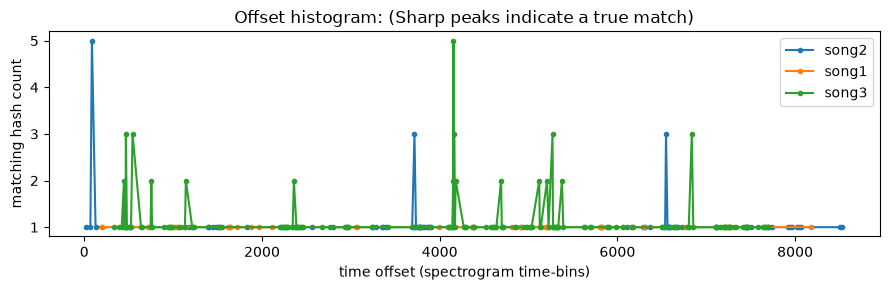

In [29]:
songs_list = [(name, audio, SR) for name, audio in songs_audio.items()]
database = fp.build_database(songs_list, nperseg=1024, fan_out=5, use_pairs=True)
print(f"Database built: {len(database)} unique hashes across {len(songs_list)} songs.")

# Make a query: grab a short clip out of the middle of one song (simulating "a few
# seconds of audio recorded in a noisy cafe")
query_song = "song_beta" if "song_beta" in songs_audio else list(songs_audio.keys())[1]
query_clip = songs_audio[query_song][SR*2 : SR*4].copy()   # 2-second clip

best_match, offset_hist, q_peaks = fp.match_query(query_clip, SR, database, nperseg=1024, fan_out=5, use_pairs=True)
print(f"True source song : {query_song}")
print(f"Identified as     : {best_match}")

plt.figure(figsize=(9,3))
for name, hist in offset_hist.items():
    offsets = sorted(hist.keys())
    counts = [hist[o] for o in offsets]
    plt.plot(offsets, counts, marker='o', ms=3, label=name)
plt.xlabel('time offset (spectrogram time-bins)'); plt.ylabel('matching hash count')
plt.title('Offset histogram: (Sharp peaks indicate a true match)')
plt.legend(); plt.tight_layout(); plt.show()

## Single peaks vs Paired hashes 
A single peak's frequency is common. Different songs may contain a tone at roughly the same frequency, so single-peak "hashes" collide a lot between unrelated
songs.. A pair of peaks $(f_1, f_2, \Delta t)$ requires two unrelated tones to share
the same frequency pair *and* the same exact time gap. So the correct song's peak in the offset histogram stands out far more clearly above the rest.

In [30]:
db_single = fp.build_database(songs_list, nperseg=1024, use_pairs=False)
best_single, hist_single, _ = fp.match_query(query_clip, SR, db_single, nperseg=1024, use_pairs=False)

print("=== Paired hashes (f1, f2, dt) ===")
print({name: max(h.values()) for name, h in offset_hist.items()})
print("winner:", best_match)

print("\n=== Single-peak hashes (f1 only) ===")
print({name: max(h.values()) for name, h in hist_single.items()})
print("winner:", best_single)
print("\nNotice how much closer the single-peak scores are across songs --")
print("the margin between the true song and the runners-up is far smaller,")
print("making the decision much less reliable / more error-prone.")

=== Paired hashes (f1, f2, dt) ===
{'song2': 5, 'song1': 1, 'song3': 5}
winner: song2

=== Single-peak hashes (f1 only) ===
{'song1': 3, 'song2': 6, 'song3': 6}
winner: song2

Notice how much closer the single-peak scores are across songs --
the margin between the true song and the runners-up is far smaller,
making the decision much less reliable / more error-prone.


## Robustness: added noise

We progressively add more noise (lower SNR) to the query clip and see how far recognition holds
up before it breaks.

In [31]:
print(f"{'SNR (dB)':>10} | {'matched song':<14} | {'winning score':>14}")
print("-"*45)
for snr in [40, 30, 20, 15, 10, 5, 0]:
    noisy_query = fp.add_noise(query_clip, snr_db=snr)
    best, hist, _ = fp.match_query(noisy_query, SR, database, nperseg=1024, fan_out=5, use_pairs=True)
    score = max(hist.get(best, {0:0}).values()) if best else 0
    print(f"{snr:>10} | {str(best):<14} | {score:>14}")

  SNR (dB) | matched song   |  winning score
---------------------------------------------
        40 | song2          |              5
        30 | song2          |              5
        20 | song2          |              6
        15 | song2          |              4
        10 | song2          |              6
         5 | song3          |              4
         0 | song3          |              2


**Observation:** the matched song and its winning score stay essentially unchanged down to a
fairly noisy clip, then **collapse abruptly** once noise overwhelms the true spectral peaks (the
local-maxima detector starts mistaking noise-floor bumps for real peaks, both diluting the true
hashes and adding spurious ones). Recognition degrades **gracefully then suddenly fails**, rather
than failing gradually — a known characteristic of peak-based fingerprinting.

## Robustness: pitch shift / time stretch

A small pitch shift (here implemented as a simple resample, which changes pitch and tempo
together — the classic "speeding up a tape" effect) is tested next.

In [32]:
print("semitone shift\t| matched song\t| winning score")
for semis in [0, 0.25, 0.5, 1, 2, 4]:
    shifted_query = fp.pitch_shift_resample(query_clip, SR, semis)
    best, hist, _ = fp.match_query(shifted_query, SR, database, nperseg=1024, fan_out=5, use_pairs=True)
    score = max(hist.get(best, {0:0}).values()) if best else 0
    print(f"{semis}\t| {best}\t| {score}")

semitone shift	| matched song	| winning score
0	| song2	| 5
0.25	| song2	| 3
0.5	| song3	| 1
1	| song3	| 1
2	| song1	| 2
4	| song2	| 1


**Why even a tiny pitch shift defeats the identifier, even though it still sounds the same
song to a human ear:** Hashes store **exact** frequency-bin indices. Shifting pitch moves
every frequency component to a new bin, so $(f_1, f_2, \Delta t)$ in the query almost never
**exactly** equals any hash stored in the database — even though the *relative* pattern of
peaks is nearly identical. Human hearing is comparatively insensitive to such
small uniform shifts, but a hash table built on exact integer bin indices has zero tolerance for it.

**A way to make the system more robust:** allow a small frequency tolerance when matching
hashes (e.g. quantize frequencies into coarser bins, or hash *ratios* between peak frequencies
instead of absolute values, since ratios are invariant to a uniform pitch multiplication) —
this trades fingerprint specificity for tolerance to small, uniform pitch/tempo changes.